In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv(r"C:\Users\Shyam A\Downloads\archive (6)\SuperMarket Analysis.csv")

In [4]:
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [5]:
df.shape

(1000, 17)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Sales                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  

In [7]:
df.describe()

,Unit price,Quantity,Tax 5%,Sales,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000


In [8]:
df.isnull().sum()

Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Sales                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

In [9]:
df.duplicated().sum()


np.int64(0)

In [10]:
df['Date'] = pd.to_datetime(df['Date'])

In [11]:
df['Date'].dtype

dtype('<M8[ns]')

In [21]:
df.dtypes

Invoice ID                         object
Branch                             object
City                               object
Customer type                      object
Gender                             object
Product line                       object
Unit price                        float64
Quantity                            int64
Tax 5%                            float64
Sales                             float64
Date                       datetime64[ns]
Time                               object
Payment                            object
cogs                              float64
gross margin percentage           float64
gross income                      float64
Rating                            float64
dtype: object

In [22]:
df['Quantity'].min()

1

In [23]:
df['Unit price'].min()

10.08

In [24]:
df['Sales'].min()

10.6785

In [25]:
df['Rating'].min(), df['Rating'].max()

(4.0, 10.0)

In [26]:
df['Sales'].describe()

count    1000.000000
mean      322.966749
std       245.885335
min        10.678500
25%       124.422375
50%       253.848000
75%       471.350250
max      1042.650000
Name: Sales, dtype: float64

In [27]:
print("Total Sales:", df['Sales'].sum())
print("Average Sales per Transaction:", df['Sales'].mean())

Total Sales: 322966.749
Average Sales per Transaction: 322.966749


In [28]:
product_sales = df.groupby('Product line')['Sales'].sum().sort_values(ascending=False)

product_sales

Product line
Food and beverages        56144.8440
Sports and travel         55122.8265
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Home and lifestyle        53861.9130
Health and beauty         49193.7390
Name: Sales, dtype: float64

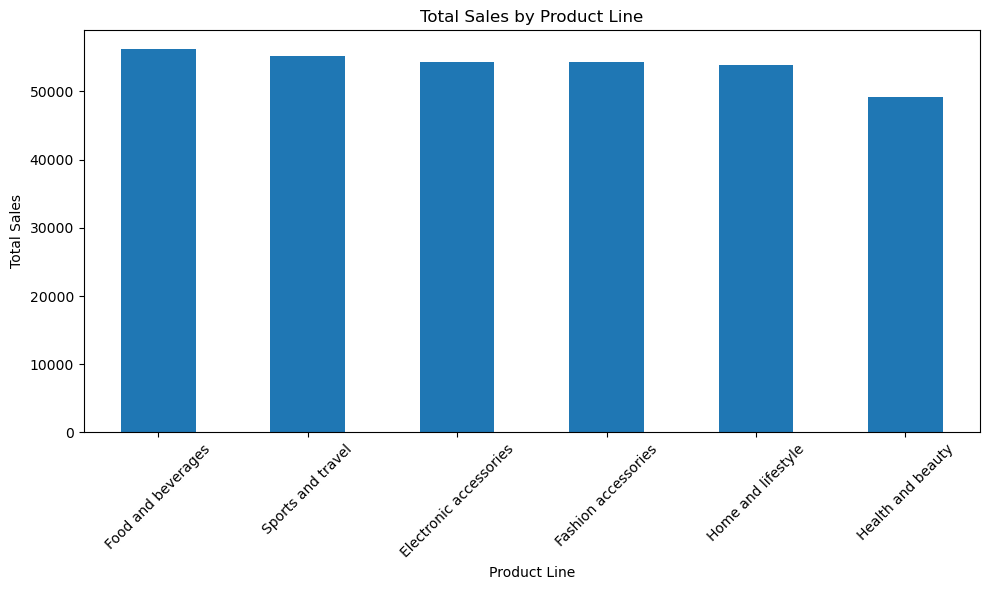

In [29]:
plt.figure(figsize=(10, 6))

product_sales.plot(kind='bar')

plt.title('Total Sales by Product Line')
plt.xlabel('Product Line')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [30]:
branch_sales = df.groupby('Branch')['Sales'].sum().sort_values(ascending=False)

branch_sales

Branch
Giza     110568.7065
Alex     106200.3705
Cairo    106197.6720
Name: Sales, dtype: float64

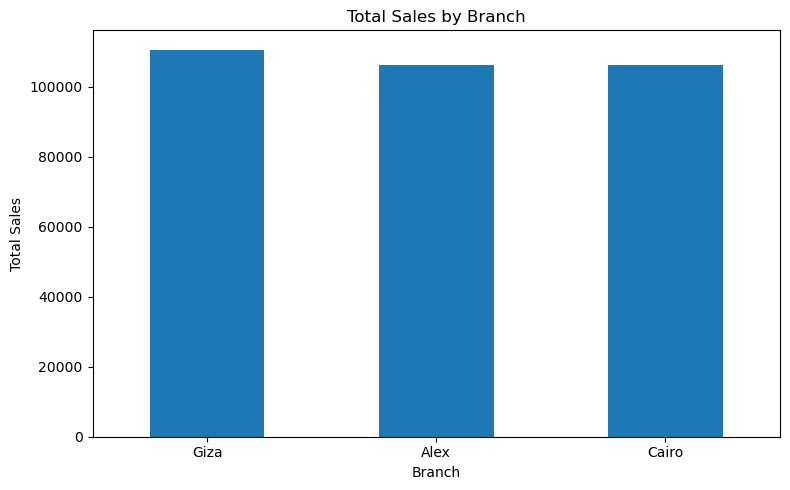

In [31]:
plt.figure(figsize=(8, 5))

branch_sales.plot(kind='bar')

plt.title('Total Sales by Branch')
plt.xlabel('Branch')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [32]:
customer_sales = df.groupby('Customer type')['Sales'].sum().sort_values(ascending=False)

customer_sales

Customer type
Member    189694.764
Normal    133271.985
Name: Sales, dtype: float64

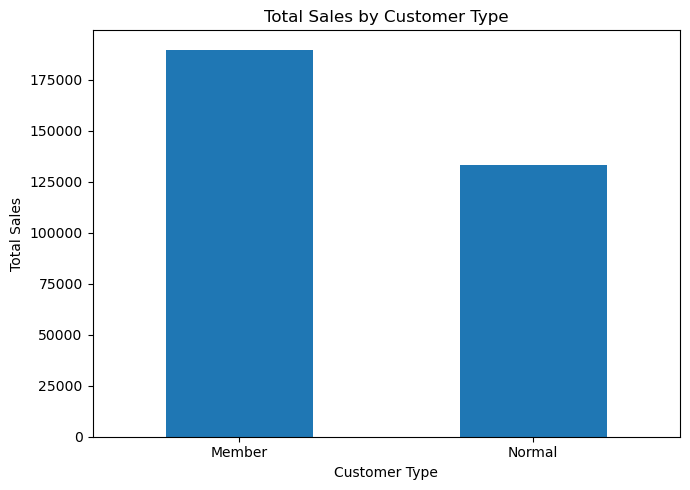

In [33]:
plt.figure(figsize=(7, 5))

customer_sales.plot(kind='bar')

plt.title('Total Sales by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [34]:
payment_counts = df['Payment'].value_counts()

payment_counts

Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64

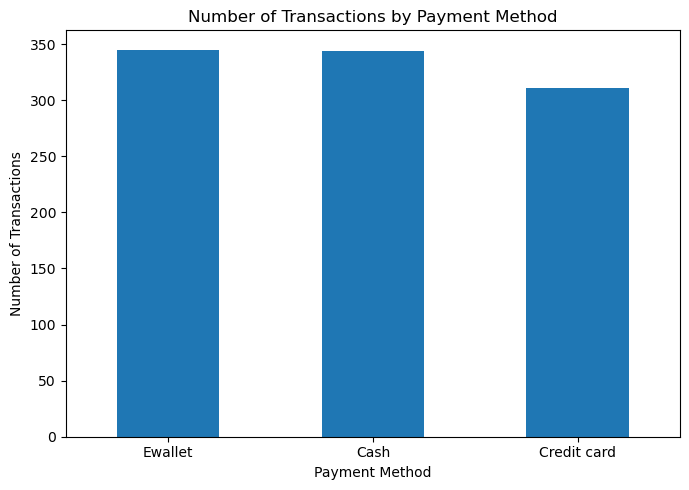

In [35]:
plt.figure(figsize=(7, 5))

payment_counts.plot(kind='bar')

plt.title('Number of Transactions by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [36]:
payment_sales = df.groupby('Payment')['Sales'].sum().sort_values(ascending=False)

payment_sales

Payment
Cash           112206.570
Ewallet        109993.107
Credit card    100767.072
Name: Sales, dtype: float64

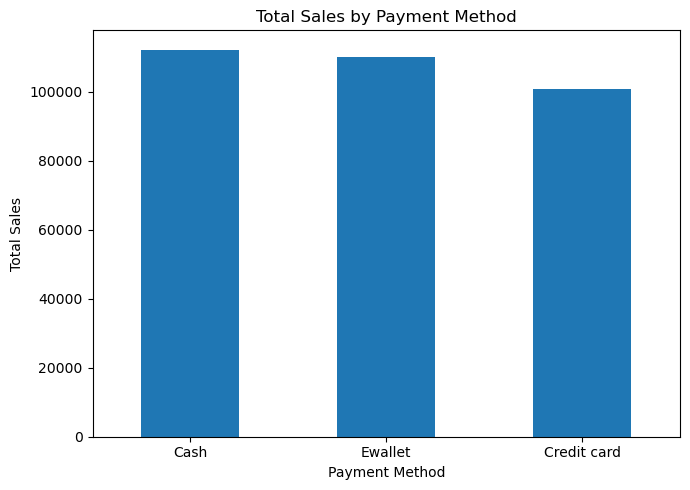

In [37]:
plt.figure(figsize=(7, 5))

payment_sales.plot(kind='bar')

plt.title('Total Sales by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [38]:
daily_sales = df.groupby('Date')['Sales'].sum()

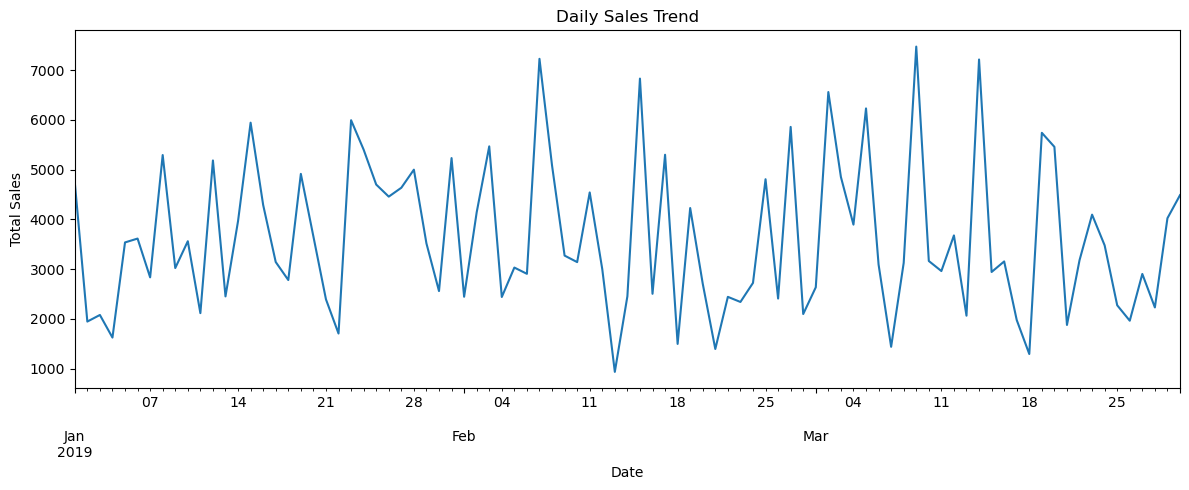

In [39]:
plt.figure(figsize=(12, 5))

daily_sales.plot()

plt.title('Daily Sales Trend')
plt.xlabel('Date')
plt.ylabel('Total Sales')

plt.tight_layout()
plt.show()

In [40]:
numeric_columns = [
    'Unit price',
    'Quantity',
    'Tax 5%',
    'Sales',
    'cogs',
    'gross margin percentage',
    'gross income',
    'Rating'
]

correlation = df[numeric_columns].corr()

correlation

,Unit price,Quantity,Tax 5%,Sales,cogs,gross margin percentage,gross income,Rating
Unit price,1.000000,0.010778,0.633962,0.633962,0.633962,NaN,0.633962,-0.008778
Quantity,0.010778,1.000000,0.705510,0.705510,0.705510,NaN,0.705510,-0.015815
Tax 5%,0.633962,0.705510,1.000000,1.000000,1.000000,NaN,1.000000,-0.036442
Sales,0.633962,0.705510,1.000000,1.000000,1.000000,NaN,1.000000,-0.036442
cogs,0.633962,0.705510,1.000000,1.000000,1.000000,NaN,1.000000,-0.036442
gross margin percentage,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gross income,0.633962,0.705510,1.000000,1.000000,1.000000,NaN,1.000000,-0.036442
Rating,-0.008778,-0.015815,-0.036442,-0.036442,-0.036442,NaN,-0.036442,1.000000


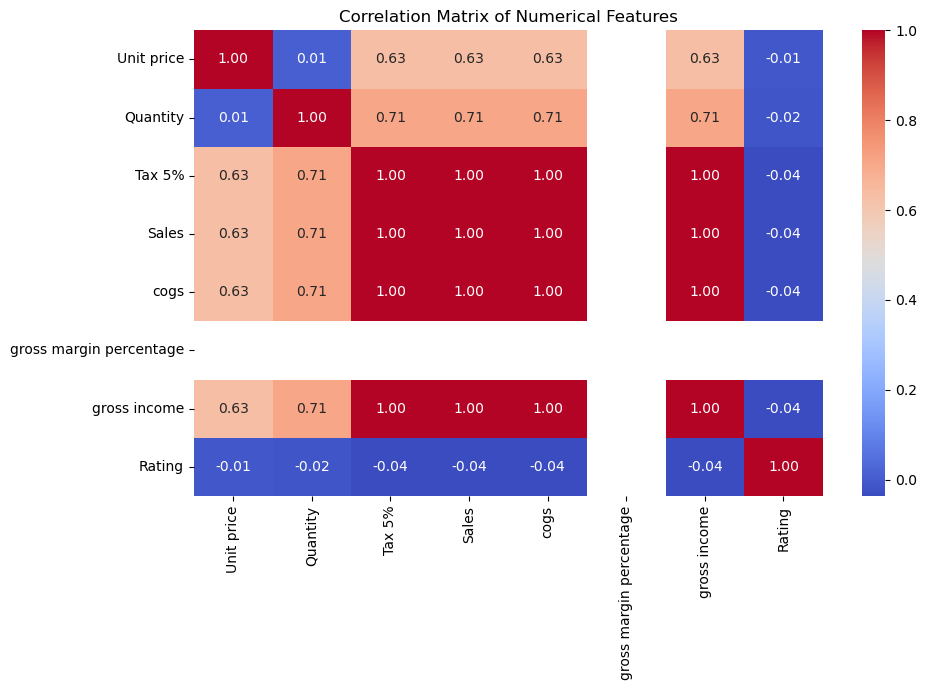

In [41]:
plt.figure(figsize=(10, 7))

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Matrix of Numerical Features')

plt.tight_layout()
plt.show()

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [43]:
features = [
    'Branch',
    'City',
    'Customer type',
    'Gender',
    'Product line',
    'Unit price',
    'Quantity',
    'Payment',
    'Rating'
]

X = df[features]
y = df['Sales']

In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [45]:
categorical_features = [
    'Branch',
    'City',
    'Customer type',
    'Gender',
    'Product line',
    'Payment'
]

numerical_features = [
    'Unit price',
    'Quantity',
    'Rating'
]

In [46]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', 'passthrough', numerical_features)
    ]
)

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [48]:
from sklearn.pipeline import Pipeline

In [49]:
linear_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

In [50]:
linear_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [51]:
y_pred_linear = linear_model.predict(X_test)

In [52]:
mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression")
print("MAE :", mae_linear)
print("RMSE:", rmse_linear)
print("R²  :", r2_linear)

Linear Regression
MAE : 59.382141579108726
RMSE: 79.89728615964353
R²  : 0.9018802054495286


In [53]:
tree_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(random_state=42))
])

In [54]:
tree_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [55]:
y_pred_tree = tree_model.predict(X_test)

In [56]:
mae_tree = mean_absolute_error(y_test, y_pred_tree)
rmse_tree = np.sqrt(mean_squared_error(y_test, y_pred_tree))
r2_tree = r2_score(y_test, y_pred_tree)

print("Decision Tree Regression")
print("MAE :", mae_tree)
print("RMSE:", rmse_tree)
print("R²  :", r2_tree)

Decision Tree Regression
MAE : 8.4932925
RMSE: 13.126982481276876
R²  : 0.9973513633429182


In [57]:
mae_linear
rmse_linear
r2_linear

mae_tree
rmse_tree
r2_tree

0.9973513633429182

In [59]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree Regression'
    ],
    'MAE': [
        mae_linear,
        mae_tree
    ],
    'RMSE': [
        rmse_linear,
        rmse_tree
    ],
    'R2 Score': [
        r2_linear,
        r2_tree
    ]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,59.382142,79.897286,0.901880
1,Decision Tree Regression,8.493293,13.126982,0.997351


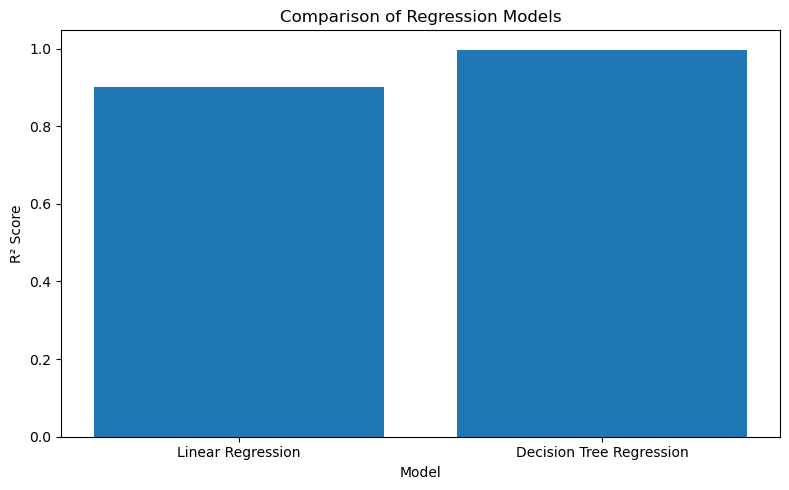

In [60]:
plt.figure(figsize=(8, 5))

plt.bar(results['Model'], results['R2 Score'])

plt.title('Comparison of Regression Models')
plt.xlabel('Model')
plt.ylabel('R² Score')

plt.tight_layout()
plt.show()

In [61]:
best_model = results.loc[results['R2 Score'].idxmax()]

print("Best Model:", best_model['Model'])
print("R² Score:", best_model['R2 Score'])
print("MAE:", best_model['MAE'])
print("RMSE:", best_model['RMSE'])

Best Model: Decision Tree Regression
R² Score: 0.9973513633429182
MAE: 8.4932925
RMSE: 13.126982481276876


In [62]:
best_predictions = y_pred_tree

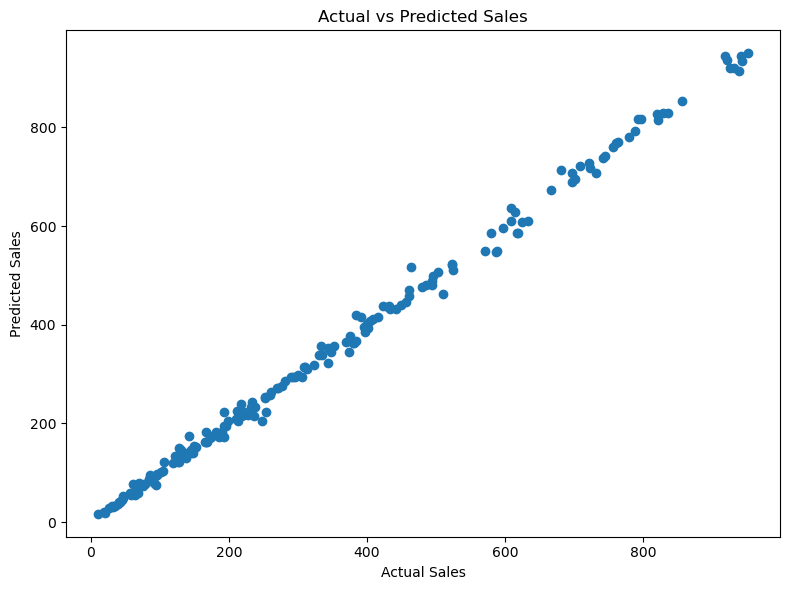

In [63]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, best_predictions)

plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales')

plt.tight_layout()
plt.show()

In [65]:
comparison = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': best_predictions
})

comparison.head(10)

,Actual Sales,Predicted Sales
0,523.9710,521.0100
1,616.9800,586.6350
2,408.7335,411.3795
3,135.3555,138.9780
4,45.9270,53.1510
5,618.9750,586.6350
6,127.8270,121.8630
7,731.6925,708.3195
8,450.1035,439.8975
9,138.1275,130.0425


## 8. Machine Learning Results

Two regression algorithms were implemented to predict supermarket sales: Linear Regression and Decision Tree Regression.

The models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

The model with the highest R² Score and comparatively lower prediction errors was considered the better-performing model for this dataset.

## 9. Key Findings

### Exploratory Data Analysis

- Food and beverages generated the highest total sales among the product lines.
- Sales performance differed between supermarket branches.
- Customer purchasing patterns varied between customer types.
- Different payment methods showed different transaction patterns.
- Sales varied over time.

### Machine Learning

- Linear Regression and Decision Tree Regression were implemented.
- Both models were evaluated using MAE, RMSE, and R² Score.
- The better-performing model was selected based on the evaluation metrics.
- The Actual vs Predicted plot was used to visually evaluate the model's predictions.

## 10. Conclusion

This project analyzed supermarket sales data using Python and explored sales patterns, product performance, branch performance, and customer purchasing behavior.

The dataset was cleaned and prepared before performing exploratory data analysis and visualization. Machine learning models were then developed to predict sales using selected transaction and customer features.

Linear Regression and Decision Tree Regression were implemented and evaluated using MAE, RMSE, and R² Score. The comparison helped identify the better-performing regression model for the dataset.

Overall, the project demonstrates an end-to-end data science workflow involving data cleaning, exploratory data analysis, visualization, feature preprocessing, machine learning, and model evaluation.